In [1]:
import pandas as pd
import os
import smarts_cerebellum.globals as gl
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import numpy as np

# DTI metrics
mcp = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_MCP_FaMap.tsv'), sep = '\t')
mcp = mcp[mcp.isPatient == 1]
for region in mcp.regionname.unique():
    for week in gl.weeks:
        rows = (mcp.Week == week)
        mcp.loc[rows, 'decentered_mean_week'] = mcp.loc[rows, 'mean'] - mcp.loc[rows, 'mean'].mean()

#mcp = mcp[mcp.regionname == 'MCP_L']


cst = pd.read_csv(os.path.join(gl.baseDir, 'MNISymC_FaMap', 'summary_MNISymC_CST_FaMap.tsv'), sep = '\t')
cst = cst[cst.isPatient == 1]
for region in cst.regionname.unique():
    for week in gl.weeks:
        rows = (cst.Week == week)
        cst.loc[rows, 'decentered_mean_week'] = cst.loc[rows, 'mean'] - cst.loc[rows, 'mean'].mean()
#cst = cst[cst.regionname == 'CST_R']

In [2]:
ipsi_cst = cst[cst.regionname == 'CST_R'].pivot(index = 'subj_id', columns = 'Week', values = 'decentered_mean_week').reset_index(drop = True)
contra_cst = cst[cst.regionname == 'CST_L'].pivot(index = 'subj_id', columns = 'Week', values = 'decentered_mean_week').reset_index(drop = True)
ipsi_mcp = mcp[mcp.regionname == 'MCP_R'].pivot(index = 'subj_id', columns = 'Week', values = 'decentered_mean_week').reset_index(drop = True)
contra_mcp = mcp[mcp.regionname == 'MCP_L'].pivot(index = 'subj_id', columns = 'Week', values = 'decentered_mean_week').reset_index(drop = True)

ipsicst_contramcp = pd.DataFrame({c: ipsi_cst.corrwith(contra_mcp[c]) for c in contra_mcp.columns})
ipsicst_ipsimcp = pd.DataFrame({c: ipsi_cst.corrwith(ipsi_mcp[c]) for c in ipsi_mcp.columns})
contracst_contramcp = pd.DataFrame({c: contra_cst.corrwith(contra_mcp[c]) for c in contra_mcp.columns})

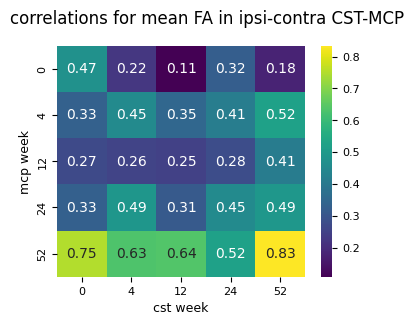

In [3]:
fig, ax = plt.subplots(figsize = (4,3))
sns.heatmap(ipsicst_contramcp, cmap = 'viridis', annot = True)
fig.suptitle("correlations for mean FA in ipsi-contra CST-MCP", y = 1)
plt.xlabel("cst week")
plt.ylabel("mcp week")
plt.show()

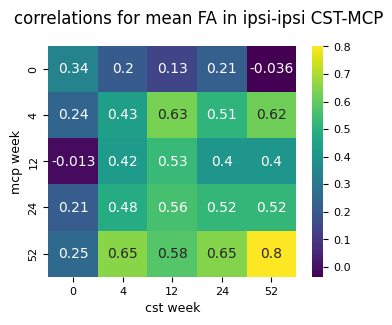

In [4]:
fig, ax = plt.subplots(figsize = (4,3))
sns.heatmap(ipsicst_ipsimcp, cmap = 'viridis', annot = True)
fig.suptitle("correlations for mean FA in ipsi-ipsi CST-MCP", y = 1)
plt.xlabel("cst week")
plt.ylabel("mcp week")
plt.show()

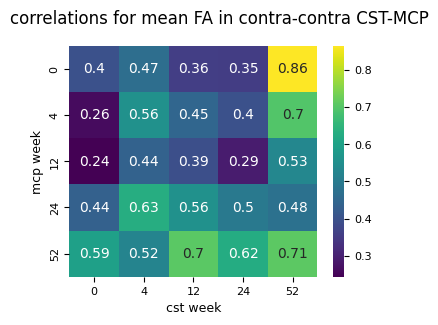

In [5]:
fig, ax = plt.subplots(figsize = (4,3))
sns.heatmap(contracst_contramcp, cmap = 'viridis', annot = True)
fig.suptitle("correlations for mean FA in contra-contra CST-MCP", y = 1)
plt.xlabel("cst week")
plt.ylabel("mcp week")
plt.show()